Segment Costs:
Step 1: P0 -> P1 | Cost (Dist): 3.61
Step 2: P1 -> P9 | Cost (Dist): 2.83
Step 3: P9 -> P4 | Cost (Dist): 3.61
Step 4: P4 -> P7 | Cost (Dist): 2.83
Step 5: P7 -> P5 | Cost (Dist): 3.16
Step 6: P5 -> P8 | Cost (Dist): 2.24
Step 7: P8 -> P3 | Cost (Dist): 2.24
Step 8: P3 -> P6 | Cost (Dist): 2.24
Step 9: P6 -> P2 | Cost (Dist): 4.12
Step 10: P2 -> P0 | Cost (Dist): 5.10

Total Route Cost: 31.96 units



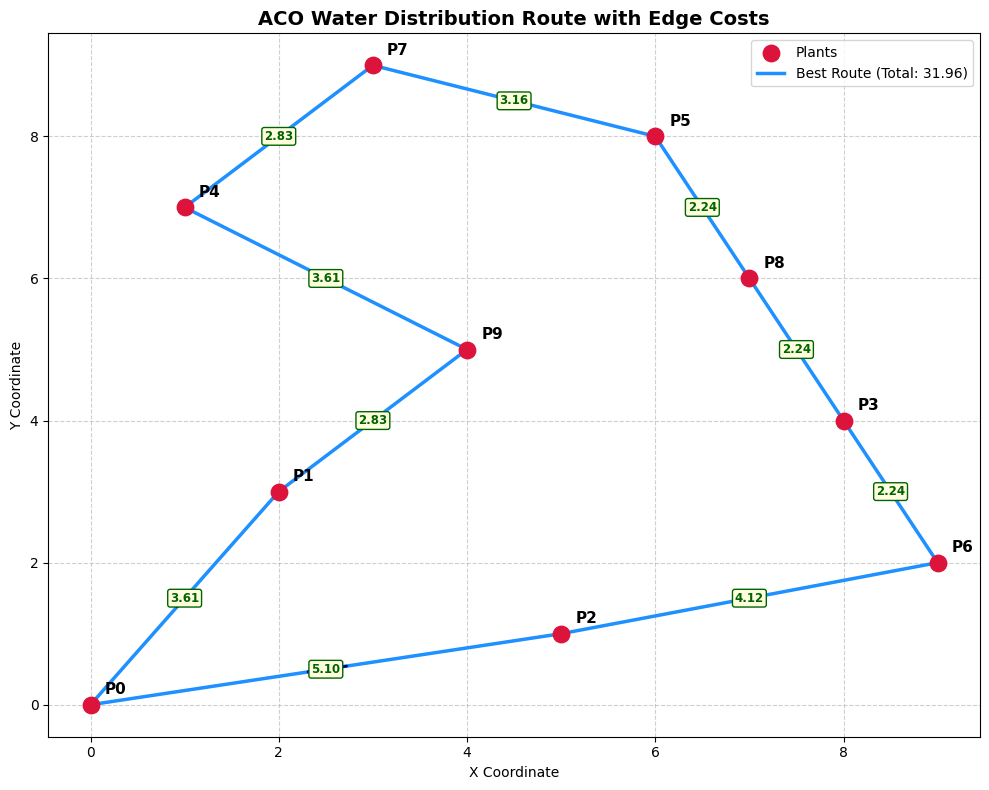

In [14]:
import numpy as np
import matplotlib.pyplot as plt

plants = np.array([
    [0, 0], [2, 3], [5, 1], [8, 4], [1, 7],
    [6, 8], [9, 2], [3, 9], [7, 6], [4, 5]
])

n_plants = len(plants)
n_ants = 10
n_iterations = 50
decay = 0.5
alpha = 1.0
beta = 2.0

dist_matrix = np.linalg.norm(plants[:, np.newaxis] - plants[np.newaxis, :], axis=2)
np.fill_diagonal(dist_matrix, np.inf)

eta = 1.0 / dist_matrix
tau = np.ones((n_plants, n_plants))

best_path = None
best_dist = float('inf')

for _ in range(n_iterations):
    paths = []
    distances = []

    for _ in range(n_ants):
        path = [0]
        visited = {0}

        while len(visited) < n_plants:
            curr = path[-1]
            unvisited = [i for i in range(n_plants) if i not in visited]

            probs = (tau[curr, unvisited] ** alpha) * (eta[curr, unvisited] ** beta)
            probs /= probs.sum()

            nxt = np.random.choice(unvisited, p=probs)
            path.append(nxt)
            visited.add(nxt)

        path.append(0)
        dist = sum(dist_matrix[path[i], path[i+1]] for i in range(n_plants))

        paths.append(path)
        distances.append(dist)

        if dist < best_dist:
            best_dist = dist
            best_path = path

    tau *= (1.0 - decay)
    for path, dist in zip(paths, distances):
        for i in range(n_plants):
            tau[path[i], path[i+1]] += 1.0 / dist
            tau[path[i+1], path[i]] += 1.0 / dist

print("Segment Costs:")
for i in range(len(best_path) - 1):
    u, v = best_path[i], best_path[i+1]
    cost = dist_matrix[u, v]
    print(f"Step {i+1}: P{u} -> P{v} | Cost (Dist): {cost:.2f}")

print(f"\nTotal Route Cost: {best_dist:.2f} units\n")

plt.figure(figsize=(10, 8))
plt.scatter(plants[:, 0], plants[:, 1], color='crimson', s=140, zorder=4, label='Plants')

for i, (x, y) in enumerate(plants):
    plt.text(x + 0.15, y + 0.15, f"P{i}", fontsize=11, fontweight='bold', zorder=5)

path_coords = plants[best_path]
plt.plot(path_coords[:, 0], path_coords[:, 1], color='dodgerblue', linewidth=2.5, linestyle='-', zorder=2, label=f'Best Route (Total: {best_dist:.2f})')

for i in range(len(best_path) - 1):
    u, v = best_path[i], best_path[i+1]
    start, end = plants[u], plants[v]
    edge_cost = dist_matrix[u, v]

    dx, dy = end[0] - start[0], end[1] - start[1]
    plt.annotate(
        '', xy=(start[0] + dx*0.55, start[1] + dy*0.55),
        xytext=(start[0] + dx*0.45, start[1] + dy*0.45),
        arrowprops=dict(arrowstyle='->', color='navy', lw=2),
        zorder=3
    )

    mid_x, mid_y = (start[0] + end[0]) / 2, (start[1] + end[1]) / 2
    plt.text(
        mid_x, mid_y, f"{edge_cost:.2f}",
        fontsize=8.5, fontweight='bold', color='darkgreen',
        bbox=dict(boxstyle='round,pad=0.2', fc='lightyellow', ec='darkgreen', lw=1),
        ha='center', va='center', zorder=5
    )

plt.title('ACO Water Distribution Route with Edge Costs', fontsize=14, fontweight='bold')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()